# Lab Mid Exam: HOG vs SIFT on Blood-Cell Images
**Name:** Ali Sher Ahmad &nbsp;&nbsp; **Reg No:** 032

## Personal settings

In [ ]:
REG_NO = "032"

SEED = int(REG_NO[-2:])                       # last two digits
last = int(REG_NO[-1])                        # last digit
HOG_CELL = (8, 8) if last % 2 == 0 else (16, 16)
GRID = 4 if last <= 4 else 6                  # 4x4 -> 16 keypoints, 6x6 -> 36 keypoints

print("Seed:", SEED, "| HOG cell:", HOG_CELL, "| SIFT grid:", f"{GRID}x{GRID}")

Seed: 32 | HOG cell: (8, 8) | SIFT grid: 4x4


In [ ]:
!pip install -q medmnist

import numpy as np, cv2, matplotlib.pyplot as plt
from medmnist import BloodMNIST
from skimage.feature import hog
from skimage import exposure
from sklearn.svm import LinearSVC
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

rng = np.random.default_rng(SEED)
CLASSES = [1, 5, 6, 7]
NAMES = {1: "eosinophil", 5: "monocyte", 6: "neutrophil", 7: "platelet"}

# Q1. Data setup

In [ ]:
def load_subset(split, n_per_class):
    ds = BloodMNIST(split=split, download=True, size=64)
    X, y = ds.imgs, ds.labels.ravel()
    idx = np.concatenate([rng.choice(np.where(y == c)[0], n_per_class, replace=False) for c in CLASSES])
    return X[idx], y[idx]

def prepare(imgs):   # RGB 64x64 -> grayscale 128x128 (uint8)
    return np.array([cv2.resize(cv2.cvtColor(im, cv2.COLOR_RGB2GRAY), (128, 128)) for im in imgs])

Xtr_raw, ytr = load_subset("train", 100)
Xva_raw, yva = load_subset("val", 30)
Xte_raw, yte = load_subset("test", 30)
Xtr, Xva, Xte = prepare(Xtr_raw), prepare(Xva_raw), prepare(Xte_raw)

for name, X, y in [("Train", Xtr, ytr), ("Val", Xva, yva), ("Test", Xte, yte)]:
    u, c = np.unique(y, return_counts=True)
    print(f"{name}: shape {X.shape}, counts", {NAMES[k]: int(v) for k, v in zip(u, c)})

Train: shape (400, 128, 128), counts {'eosinophil': 100, 'monocyte': 100, 'neutrophil': 100, 'platelet': 100}
Val: shape (120, 128, 128), counts {'eosinophil': 30, 'monocyte': 30, 'neutrophil': 30, 'platelet': 30}
Test: shape (120, 128, 128), counts {'eosinophil': 30, 'monocyte': 30, 'neutrophil': 30, 'platelet': 30}


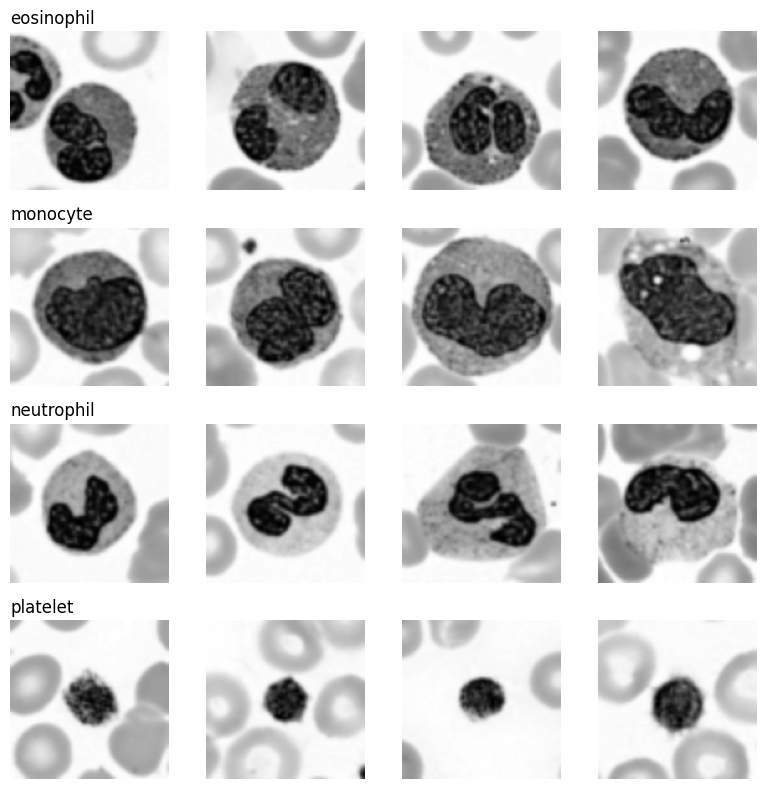

In [ ]:
fig, ax = plt.subplots(4, 4, figsize=(8, 8))
for r, c in enumerate(CLASSES):
    for j, i in enumerate(np.where(ytr == c)[0][:4]):
        ax[r, j].imshow(Xtr[i], cmap="gray"); ax[r, j].axis("off")
    ax[r, 0].set_title(NAMES[c], loc="left")
plt.tight_layout(); plt.show()

# Q2. HOG + SVM

### (a) HOG features

In [ ]:
def hog_features(imgs):
    return np.array([hog(im, orientations=9, pixels_per_cell=HOG_CELL,
                         cells_per_block=(2, 2), block_norm="L2-Hys") for im in imgs])

Htr, Hva = hog_features(Xtr), hog_features(Xva)
print("HOG feature length:", Htr.shape[1])

HOG feature length: 8100


**Hand calculation of HOG length** (128 x 128 image, 9 orientations, 2 x 2 cells per block, block stride = 1 cell)

*My cell = 8 x 8 (last digit 2 is even):* cells = 128/8 = 16 per side → blocks = 16 − 2 + 1 = 15 per side → 15 × 15 = 225 blocks.
Each block = 2 × 2 cells × 9 bins = 36 values → **225 × 36 = 8100**.

### (b) HOG picture for one image per class

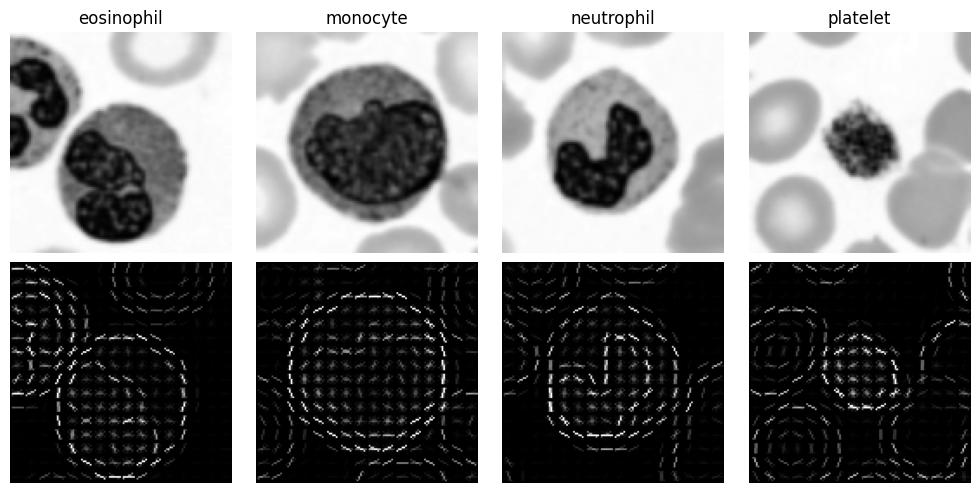

In [ ]:
fig, ax = plt.subplots(2, 4, figsize=(10, 5))
for k, c in enumerate(CLASSES):
    im = Xtr[np.where(ytr == c)[0][0]]
    _, vis = hog(im, orientations=9, pixels_per_cell=HOG_CELL, cells_per_block=(2, 2), visualize=True)
    ax[0, k].imshow(im, cmap="gray"); ax[0, k].set_title(NAMES[c])
    ax[1, k].imshow(exposure.rescale_intensity(vis, in_range=(0, vis.max() / 2)), cmap="gray")
    ax[0, k].axis("off"); ax[1, k].axis("off")
plt.tight_layout(); plt.show()

### (c) Train SVM, choose C on validation

In [ ]:
def train_choose_C(Ftr, Fva):
    best = None
    for C in [0.1, 1, 10]:
        model = make_pipeline(StandardScaler(), LinearSVC(C=C, max_iter=10000, random_state=SEED))
        model.fit(Ftr, ytr)
        acc = accuracy_score(yva, model.predict(Fva))
        print(f"C = {C:<4} validation accuracy = {acc:.3f}")
        if best is None or acc > best[0]:
            best = (acc, C, model)
    print("Best C:", best[1])
    return best[2]

def report(model, Fva, title):
    pred = model.predict(Fva)
    print(f"{title}: val accuracy = {accuracy_score(yva, pred):.3f}, macro-F1 = {f1_score(yva, pred, average='macro'):.3f}")
    cm = confusion_matrix(yva, pred, labels=CLASSES)
    ConfusionMatrixDisplay(cm, display_labels=[NAMES[c] for c in CLASSES]).plot(cmap="Blues")
    plt.title(title + " (validation)"); plt.xticks(rotation=30); plt.show()
    return cm

hog_svm = train_choose_C(Htr, Hva)
cm_hog = report(hog_svm, Hva, "HOG + SVM")

C = 0.1  validation accuracy = 0.725


# Q3. SIFT + SVM

### (a) Normal SIFT detection

In [ ]:
sift = cv2.SIFT_create()
counts = np.array([len(sift.detectAndCompute(im, None)[0]) for im in Xtr])
print(f"Keypoints per image: avg = {counts.mean():.1f}, min = {counts.min()}, max = {counts.max()}")
print("Images with zero keypoints:", np.sum(counts == 0))

kp, _ = sift.detectAndCompute(Xtr[0], None)
out = cv2.drawKeypoints(Xtr[0], kp, None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
plt.imshow(out); plt.title(f"{len(kp)} SIFT keypoints ({NAMES[ytr[0]]})"); plt.axis("off"); plt.show()

**Why is this a problem for an SVM?** An SVM needs every image to be one vector of the same fixed length, but normal SIFT gives a different number of 128-D descriptors per image (even zero), so the images cannot be stacked into one feature matrix.

### (b) Fixed grid of keypoints

In [ ]:
step = 128 / GRID
grid_kps = [cv2.KeyPoint(float(step / 2 + j * step), float(step / 2 + i * step), 32)
            for i in range(GRID) for j in range(GRID)]

def sift_grid_features(imgs):
    return np.array([sift.compute(im, grid_kps)[1].ravel() for im in imgs])

Str, Sva = sift_grid_features(Xtr), sift_grid_features(Xva)
print("Grid points:", len(grid_kps), "| SIFT feature length:", Str.shape[1])

**Hand calculation of SIFT length:** each keypoint gives a 128-D descriptor (4 × 4 sub-regions × 8 orientation bins = 128).

*My grid = 4 × 4 (last digit 2 is in 0–4):* 16 points × 128 = **2048**.

### (c) Train SVM, choose C on validation

C = 0.1  validation accuracy = 0.708
C = 1    validation accuracy = 0.708
C = 10   validation accuracy = 0.700
Best C: 0.1
SIFT + SVM: val accuracy = 0.708, macro-F1 = 0.712


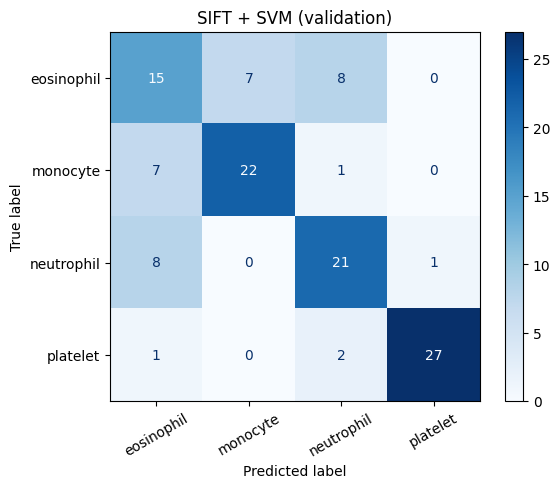

In [ ]:
sift_svm = train_choose_C(Str, Sva)
cm_sift = report(sift_svm, Sva, "SIFT + SVM")

# Q4. Robustness

### Prediction (written before running)
- **Rotation:** I expect **HOG** to lose more accuracy, because its cells are small and fixed on the image, so rotating the cell moves its edges into different cells and changes their gradient directions; the grid-SIFT patches are larger (32 px) with Gaussian weighting, so they tolerate small shifts better.
- **Noise:** I expect **HOG** to lose more accuracy, because small cells compute gradients from only a few pixels and noise creates many false gradients, while each SIFT descriptor pools gradients over a much larger patch, which averages the noise out.

In [ ]:
def rotate(imgs, angle=20):
    M = cv2.getRotationMatrix2D((64, 64), angle, 1.0)
    return np.array([cv2.warpAffine(im, M, (128, 128), borderMode=cv2.BORDER_REFLECT) for im in imgs])

def add_noise(imgs, sigma=0.05):
    noise_rng = np.random.default_rng(SEED)
    x = imgs / 255.0 + noise_rng.normal(0, sigma, imgs.shape)
    return (np.clip(x, 0, 1) * 255).astype(np.uint8)

tests = {"Clean": Xte, "Rotated": rotate(Xte), "Noisy": add_noise(Xte)}
results = {"HOG + SVM": [], "SIFT + SVM": []}
for name, imgs in tests.items():   # models are frozen: only predict, no fitting
    results["HOG + SVM"].append(accuracy_score(yte, hog_svm.predict(hog_features(imgs))))
    results["SIFT + SVM"].append(accuracy_score(yte, sift_svm.predict(sift_grid_features(imgs))))

print(f"{'Model':<12}{'Clean':>8}{'Rotated':>10}{'Noisy':>8}")
for m, r in results.items():
    print(f"{m:<12}{r[0]:>8.3f}{r[1]:>10.3f}{r[2]:>8.3f}")

Model          Clean   Rotated   Noisy
HOG + SVM      0.725     0.717   0.250
SIFT + SVM     0.775     0.775   0.783


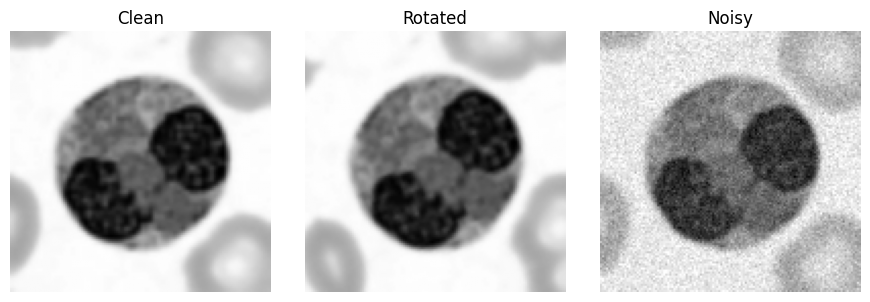

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(9, 3))
for a, (name, imgs) in zip(ax, tests.items()):
    a.imshow(imgs[0], cmap="gray"); a.set_title(name); a.axis("off")
plt.tight_layout(); plt.show()

| Model | Clean accuracy | Rotated accuracy | Noisy accuracy |
|---|---|---|---|
| HOG + SVM | 0.725 | 0.717 | 0.250 |
| SIFT + SVM | 0.775 | 0.775 | 0.783 |

**Was my prediction correct?** Partly. Under noise my prediction was correct: HOG + SVM collapsed from 0.725 to 0.250 (chance level for 4 classes), while SIFT + SVM stayed stable at 0.783 versus 0.775 clean, because each 32-pixel SIFT patch averages out the noise. Under rotation HOG did lose more than SIFT (0.725 → 0.717 versus 0.775 → 0.775), but the drop was only 0.008, which is a single test image out of 120, so a 20° rotation barely affected either model and this part is too small to call a clear win.

# Q5. Short answers and AI log

**(a) Why does HOG use block normalisation?** Gradient magnitudes change with lighting and contrast, so the same cell can look very different in a bright or dark image. Normalising each 2 × 2 block of cell histograms by its L2 norm makes the feature depend on edge *shape and direction* rather than absolute brightness, and overlapping blocks make it more stable.

**(b) Why is it wrong to choose C using the test set?** If the test set is used to pick C, the test set has influenced the model, so the test accuracy becomes optimistically biased and is no longer an honest estimate of performance on unseen images. The validation set is for tuning; the test set is used only once, at the end.

In [ ]:
def most_confused(cm):
    off = cm.copy(); np.fill_diagonal(off, 0)
    sym = off + off.T
    i, j = np.unravel_index(sym.argmax(), sym.shape)
    return NAMES[CLASSES[i]], NAMES[CLASSES[j]], sym[i, j]

print("HOG most confused pair :", most_confused(cm_hog)[:2], int(most_confused(cm_hog)[2]))
print("SIFT most confused pair:", most_confused(cm_sift)[:2], int(most_confused(cm_sift)[2]))

HOG most confused pair : ('eosinophil', 'neutrophil') 17
SIFT most confused pair: ('eosinophil', 'neutrophil') 16


**Most confused classes:** **eosinophil and neutrophil** for both models (HOG: 17 mistakes between them, SIFT: 16 on the validation set). These are both white blood cells of similar size and round shape; they differ mostly in nucleus shape and in the **colour** of the cytoplasm granules (e.g. eosinophils have red-orange granules, neutrophils pale/lilac ones). Converting to grayscale removes that colour cue, so the models only see shape and texture, which look much more alike.

**AI log**

| Prompt (one line) | What I changed | How I checked it was correct |
|---|---|---|
| “Solve my HOG vs SIFT lab mid on BloodMNIST and explain the code for viva” (Claude) | Set REG_NO = "032", so seed = 32, HOG cell 8×8 and SIFT grid 4×4. Rewrote the Q4 prediction in my own words. Filled the Q4 table and Q5 answers from my outputs. | Printed shapes (400/120/120, each 128×128) and class counts (100/30/30 per class). The HOG length 8100 matched my hand calculation (15×15×36). The SIFT length 2048 matched 16×128. Viewed the image grid, HOG pictures and SIFT keypoint drawing. |